# MIND-Crypt Analysis: SPECK32/64 Indistinguishability Across All 22 Rounds

This notebook analyzes and visualizes the **MIND-Crypt** framework ([arXiv:2405.19683](https://arxiv.org/html/2405.19683v1)) applied to **SPECK32/64** across **every single round from 1 to 22**, comparing CBC indistinguishability against Gohr's differential cryptanalysis and bit-level diffusion.

### What This Notebook Covers
1. **Full Round 1 → 22 Sweep (DeepAnalyst CBC, TransferAnalyst CBC, and Gohr Differential):** Compares all 22 rounds side by side from `results/exp_a_r1_22.csv`, `results/exp_b_r1_22.csv`, and `results/exp_c_gohr_r1_22.csv`.
2. **Part 1 Paper Matrix (`R ∈ {5, 6, 21, 22}`):** Visualizes sample-size scaling (`5k, 10k, 25k` per class) across Tables 1–6.
3. **Memorization vs. Generalization Diagnostics:** Tracks training vs. validation accuracy/loss across epochs to separate overfitting from genuine cryptanalytic leakage.
4. **Architecture Sanity Ablation & ROC Analysis:** Proves the 1D-ResNet works when statistical bias exists (**Random-IV CBC** vs. **Fixed-IV CBC** vs. **Gohr 5-Round Differential**).
5. **Avalanche & Bit-Diffusion Sweep (Rounds 1 → 22):** Measures single-bit flip propagation across all 22 rounds (`22 × 32` heatmap).


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix

PROJECT_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from crypto.speck import Speck32_64, check_speck_testvector, enc_round, PAPER_KEY_1_BYTES
from crypto.cbc_generator import CBCDatasetGenerator, convert_to_binary_32
from crypto.gohr_generator import generate_gohr_splits
from models.resnet_distinguisher import ResNetDistinguisher, train_model, evaluate_model
from models.dataset import create_dataloaders

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert check_speck_testvector(), "SPECK32/64 NSA test vector verification failed!"
print(f"Project root: {PROJECT_ROOT}")
print(f"Device: {device} | PyTorch: {torch.__version__} | SPECK32/64 NSA test vector: PASSED")


Project root: /home/hatem/Ai/mini-project/speck-sight
Device: cpu | PyTorch: 2.15.0+cu132 | SPECK32/64 NSA test vector: PASSED


## 1. Full Round 1 → 22 Evaluation (`exp_a_r1_22`, `exp_b_r1_22`, `exp_c_gohr_r1_22`)

We load the full **22-round** results generated by:
```bash
python run_all.py --profile quick --all-rounds --tl-sizes 10000 --run-gohr --gohr-train-samples 50000 --gohr-epochs 8
```
* **DeepAnalyst (Random-IV CBC):** Trained on `K1` and evaluated on `K1` / `K2` for every round `1..22`.
* **TransferAnalyst (Random-IV CBC):** Frozen `K1` ResNet features + XGBoost (`10k` samples/class) across `1..22`.
* **Gohr Differential (`Δ=(0x0040, 0)`):** Same 1D-ResNet architecture (`num_channels=4`) trained on differential vs. random pairs over unseen random keys across `1..22`.


In [2]:
df_a22 = pd.read_csv(os.path.join(PROJECT_ROOT, "results", "exp_a_r1_22.csv"))
df_b22 = pd.read_csv(os.path.join(PROJECT_ROOT, "results", "exp_b_r1_22.csv"))
df_c22 = pd.read_csv(os.path.join(PROJECT_ROOT, "results", "exp_c_gohr_r1_22.csv"))

cbc_same_k = df_a22[df_a22["scenario"] == "Same Round, Same Key"][["eval_round", "accuracy"]].rename(
    columns={"eval_round": "rounds", "accuracy": "CBC_DL_SameKey_Acc"}
)
cbc_diff_k = df_a22[df_a22["scenario"] == "Same Round, Different Key"][["eval_round", "accuracy"]].rename(
    columns={"eval_round": "rounds", "accuracy": "CBC_DL_DiffKey_Acc"}
)
cbc_tl_k2 = df_b22[df_b22["scenario"] == "Same Round, Different Key"][["eval_round", "accuracy"]].rename(
    columns={"eval_round": "rounds", "accuracy": "CBC_TL_DiffKey_Acc"}
)
gohr_df = df_c22[["rounds", "accuracy", "roc_auc"]].rename(
    columns={"accuracy": "Gohr_Diff_Acc", "roc_auc": "Gohr_Diff_AUC"}
)

merged_22 = (
    gohr_df
    .merge(cbc_same_k, on="rounds")
    .merge(cbc_diff_k, on="rounds")
    .merge(cbc_tl_k2, on="rounds")
)
display(merged_22.set_index("rounds"))


,Gohr_Diff_Acc,Gohr_Diff_AUC,CBC_DL_SameKey_Acc,CBC_DL_DiffKey_Acc,CBC_TL_DiffKey_Acc
rounds,,,,,
1,1.0000,1.0000,0.5060,0.4961,0.4999
2,0.9994,1.0000,0.5008,0.4990,0.5070
3,0.9962,0.9999,0.5040,0.5028,0.4971
4,0.9487,0.9855,0.5028,0.5021,0.5013
5,0.8589,0.9152,0.4984,0.4954,0.4961
6,0.6617,0.7021,0.5004,0.4995,0.4968
7,0.5028,0.5058,0.4983,0.4998,0.4961
8,0.5094,0.5117,0.5013,0.4985,0.5053
9,0.5009,0.4990,0.5058,0.5027,0.4970


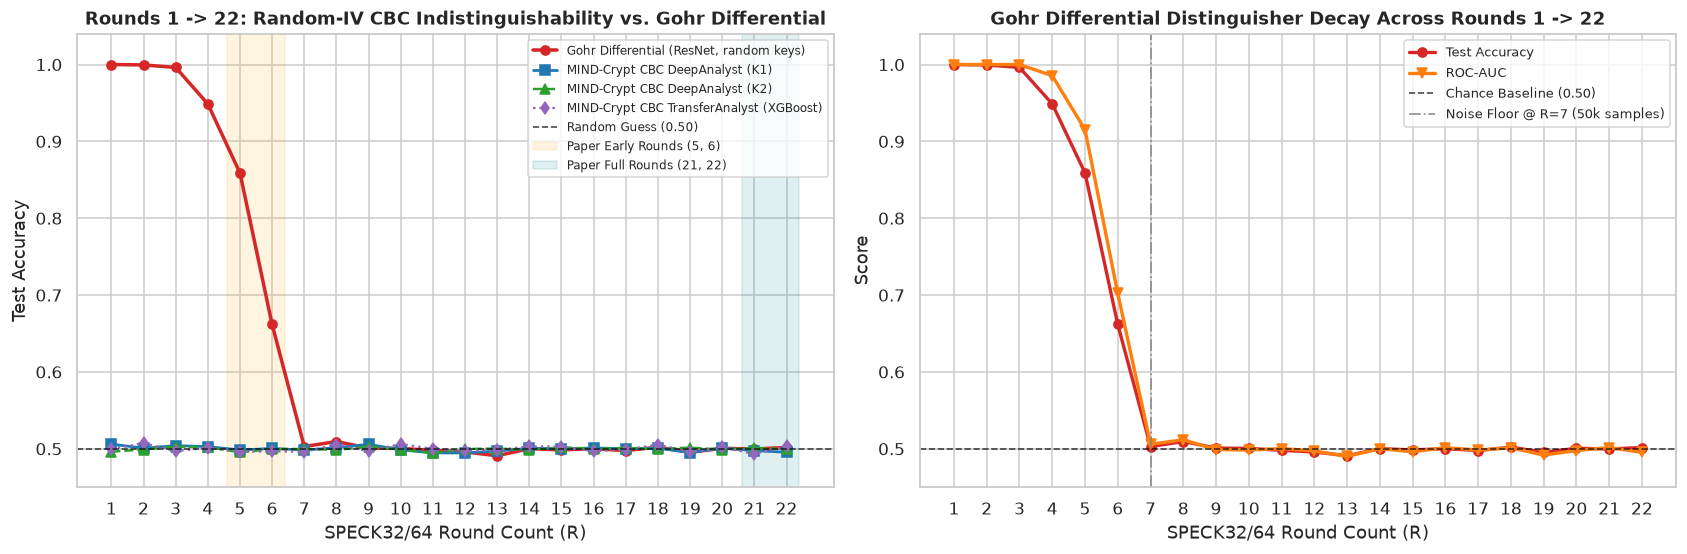

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
r_axis = merged_22["rounds"]

# Left Panel: CBC vs. Gohr Differential across ALL 22 rounds
axes[0].plot(r_axis, merged_22["Gohr_Diff_Acc"], marker="o", linewidth=2.3, color="#d62728", label="Gohr Differential (ResNet, random keys)")
axes[0].plot(r_axis, merged_22["CBC_DL_SameKey_Acc"], marker="s", linewidth=1.8, color="#1f77b4", label="MIND-Crypt CBC DeepAnalyst (K1)")
axes[0].plot(r_axis, merged_22["CBC_DL_DiffKey_Acc"], marker="^", linewidth=1.6, linestyle="--", color="#2ca02c", label="MIND-Crypt CBC DeepAnalyst (K2)")
axes[0].plot(r_axis, merged_22["CBC_TL_DiffKey_Acc"], marker="d", linewidth=1.6, linestyle=":", color="#9467bd", label="MIND-Crypt CBC TransferAnalyst (XGBoost)")
axes[0].axhline(0.50, color="black", linestyle="--", linewidth=1.1, alpha=0.7, label="Random Guess (0.50)")
axes[0].axvspan(4.6, 6.4, color="orange", alpha=0.12, label="Paper Early Rounds (5, 6)")
axes[0].axvspan(20.6, 22.4, color="teal", alpha=0.12, label="Paper Full Rounds (21, 22)")
axes[0].set_xticks(r_axis)
axes[0].set_ylim(0.45, 1.04)
axes[0].set_title("Rounds 1 -> 22: Random-IV CBC Indistinguishability vs. Gohr Differential", fontweight="bold")
axes[0].set_xlabel("SPECK32/64 Round Count (R)")
axes[0].set_ylabel("Test Accuracy")
axes[0].legend(fontsize=8, loc="upper right")

# Right Panel: Gohr Differential Accuracy vs. ROC-AUC across Rounds 1..22
axes[1].plot(r_axis, merged_22["Gohr_Diff_Acc"], marker="o", linewidth=2.2, color="#d62728", label="Test Accuracy")
axes[1].plot(r_axis, merged_22["Gohr_Diff_AUC"], marker="v", linewidth=2.2, color="#ff7f0e", label="ROC-AUC")
axes[1].axhline(0.50, color="black", linestyle="--", linewidth=1.1, alpha=0.7, label="Chance Baseline (0.50)")
axes[1].axvline(7, color="gray", linestyle="-.", linewidth=1.2, alpha=0.8, label="Noise Floor @ R=7 (50k samples)")
axes[1].set_xticks(r_axis)
axes[1].set_ylim(0.45, 1.04)
axes[1].set_title("Gohr Differential Distinguisher Decay Across Rounds 1 -> 22", fontweight="bold")
axes[1].set_xlabel("SPECK32/64 Round Count (R)")
axes[1].set_ylabel("Score")
axes[1].legend(fontsize=8.5, loc="upper right")

plt.tight_layout()
plt.show()


## 2. Part 1 Paper Evaluation Matrix (`R ∈ {5, 6, 21, 22}` & Sample-Size Scaling)

Visualizes `results/exp_a_results.csv` and `results/exp_b_results.csv` across the paper's 4 evaluation scenarios and sample-size sweep (`5k, 10k, 25k` per class).


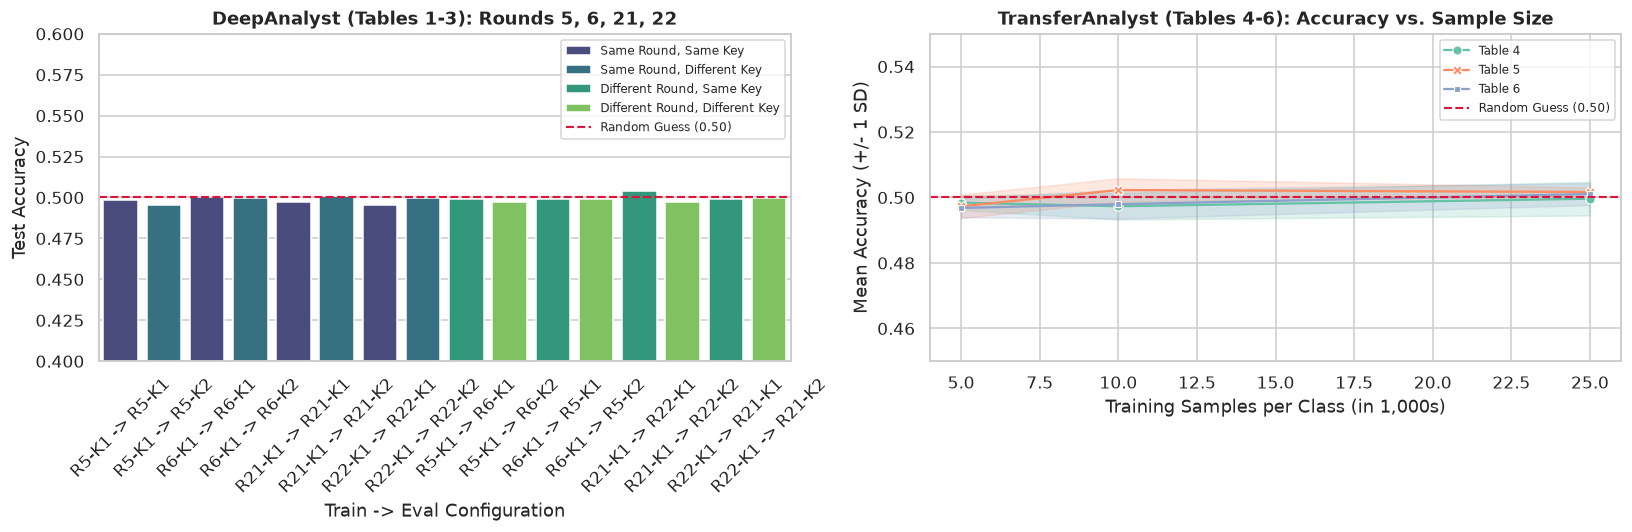

In [4]:
df_a = pd.read_csv(os.path.join(PROJECT_ROOT, "results", "exp_a_results.csv"))
df_b = pd.read_csv(os.path.join(PROJECT_ROOT, "results", "exp_b_results.csv"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.0))

df_a_plot = df_a.copy()
df_a_plot["pair_label"] = (
    "R" + df_a_plot["train_round"].astype(str) + "-" + df_a_plot["train_key"]
    + " -> R" + df_a_plot["eval_round"].astype(str) + "-" + df_a_plot["eval_key"]
)
sns.barplot(
    data=df_a_plot, x="pair_label", y="accuracy", hue="scenario",
    ax=axes[0], dodge=False, palette="viridis"
)
axes[0].axhline(0.50, color="crimson", linestyle="--", linewidth=1.4, label="Random Guess (0.50)")
axes[0].set_ylim(0.40, 0.60)
axes[0].set_title("DeepAnalyst (Tables 1-3): Rounds 5, 6, 21, 22", fontweight="bold")
axes[0].set_xlabel("Train -> Eval Configuration")
axes[0].set_ylabel("Test Accuracy")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8, loc="upper right")

df_b_plot = df_b.copy()
df_b_plot["samples_k"] = df_b_plot["samples_per_class"] / 1000.0
sns.lineplot(
    data=df_b_plot, x="samples_k", y="accuracy", hue="table", style="table",
    markers=True, dashes=False, errorbar="sd", ax=axes[1], palette="Set2"
)
axes[1].axhline(0.50, color="crimson", linestyle="--", linewidth=1.4, label="Random Guess (0.50)")
axes[1].set_ylim(0.45, 0.55)
axes[1].set_title("TransferAnalyst (Tables 4-6): Accuracy vs. Sample Size", fontweight="bold")
axes[1].set_xlabel("Training Samples per Class (in 1,000s)")
axes[1].set_ylabel("Mean Accuracy (+/- 1 SD)")
axes[1].legend(fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()


## 3. Memorization vs. Generalization (Random-IV CBC Training Curve)

Under uniform random 32-bit IVs ($C = \text{SPECK}_K^{(R)}(P \oplus IV)$), the cipher input is uniformly distributed for both $P_1$ and $P_2$. Plotting **Training vs. Validation** loss and accuracy on Round 5 (`K1`) reveals how training memorization diverges from unseen-test generalization (`~0.50`).


Random-IV CBC (R=5) Final Train Acc: 0.6560 | Test Acc: 0.4978


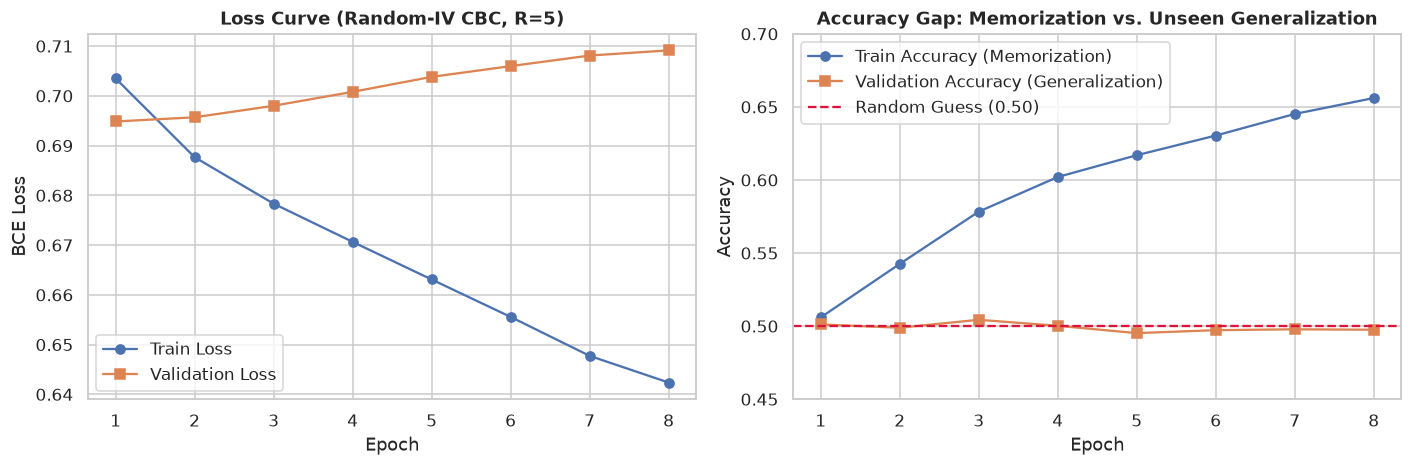

In [5]:
gen_cbc = CBCDatasetGenerator(key=PAPER_KEY_1_BYTES, rounds=5, seed=42)
cbc_splits = gen_cbc.generate_split_dataset(
    train_samples_per_class=15_000,
    val_samples_per_class=5_000,
    test_samples_per_class=10_000,
    iv_mode="random",
)
cbc_loaders = create_dataloaders(cbc_splits, batch_size=2048)

torch.manual_seed(42)
model_cbc_rand = ResNetDistinguisher(num_filters=32, depth=1, d1=64, d2=64, num_channels=2)
hist_cbc_rand = train_model(
    model_cbc_rand, cbc_loaders["train"], cbc_loaders["val"],
    epochs=8, lr=0.002, scheduler_type="cyclic", cycle_epochs=8, load_best=False, verbose=False,
)
eval_cbc_rand = evaluate_model(model_cbc_rand, cbc_loaders["test"], device=device)
print(f"Random-IV CBC (R=5) Final Train Acc: {hist_cbc_rand['train_acc'][-1]:.4f} | Test Acc: {eval_cbc_rand['accuracy']:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
epochs_axis = range(1, len(hist_cbc_rand["train_loss"]) + 1)

axes[0].plot(epochs_axis, hist_cbc_rand["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs_axis, hist_cbc_rand["val_loss"], marker="s", label="Validation Loss")
axes[0].set_title("Loss Curve (Random-IV CBC, R=5)", fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].legend()

axes[1].plot(epochs_axis, hist_cbc_rand["train_acc"], marker="o", label="Train Accuracy (Memorization)")
axes[1].plot(epochs_axis, hist_cbc_rand["val_acc"], marker="s", label="Validation Accuracy (Generalization)")
axes[1].axhline(0.50, color="crimson", linestyle="--", label="Random Guess (0.50)")
axes[1].set_title("Accuracy Gap: Memorization vs. Unseen Generalization", fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0.45, 0.70)
axes[1].legend()

plt.tight_layout()
plt.show()


## 4. Sanity Ablation, ROC Curves & Confusion Matrix (Round 5)

Comparing **Random-IV CBC**, **Fixed-IV CBC**, and **Gohr 5-Round Differential** (`Δ = (0x0040, 0)`, random keys) on the same `ResNetDistinguisher` architecture.


Fixed-IV CBC (R=5):      {'accuracy': 1.0, 'tpr': 1.0, 'tnr': 1.0, 'loss': 0.029404923766851426}
Gohr Differential (R=5): {'accuracy': 0.86825, 'tpr': 0.8175, 'tnr': 0.919, 'loss': 0.32393936067819595}


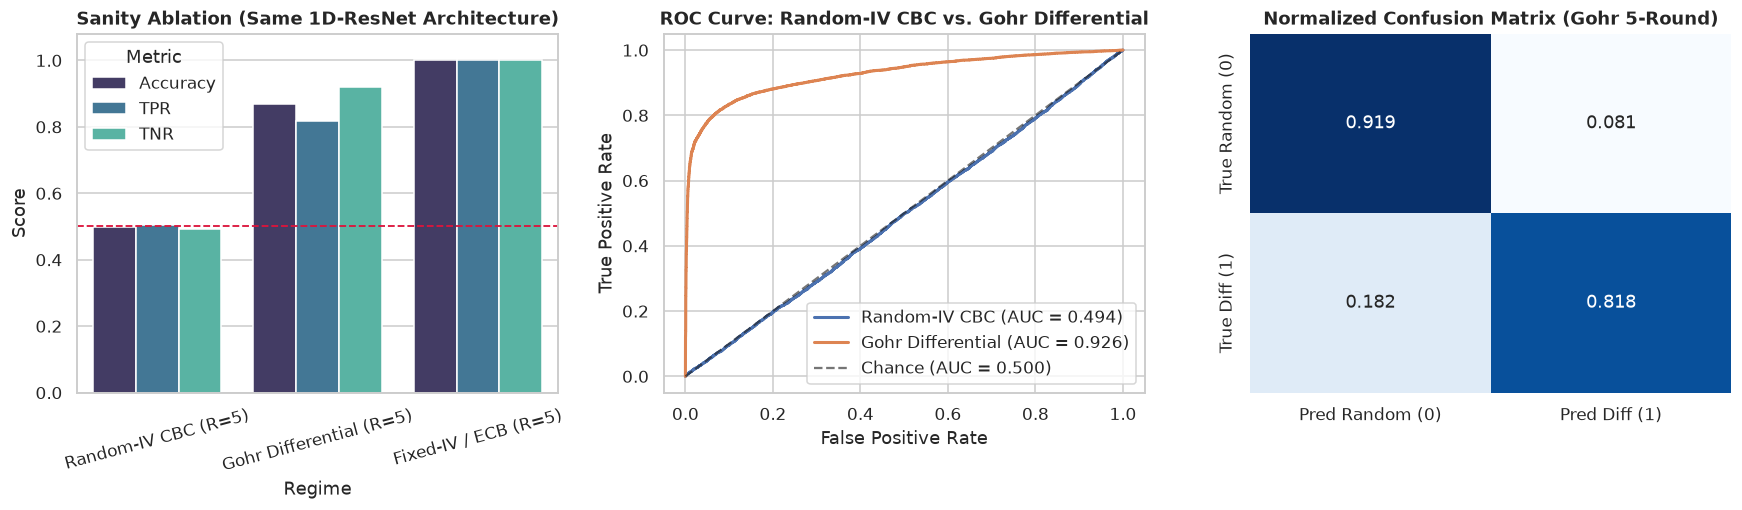

In [6]:
fixed_splits = gen_cbc.generate_split_dataset(
    train_samples_per_class=5_000, val_samples_per_class=1_000, test_samples_per_class=2_000, iv_mode="fixed"
)
fixed_loaders = create_dataloaders(fixed_splits, batch_size=512)
torch.manual_seed(42)
model_fixed = ResNetDistinguisher(num_filters=32, depth=1, d1=64, d2=64, num_channels=2)
train_model(model_fixed, fixed_loaders["train"], fixed_loaders["val"], epochs=3, lr=0.003, verbose=False)
eval_fixed = evaluate_model(model_fixed, fixed_loaders["test"], device=device)

gohr_splits = generate_gohr_splits(n_train=100_000, n_val=20_000, n_test=20_000, rounds=5, seed=101)
gohr_loaders = create_dataloaders(gohr_splits, batch_size=5000)
torch.manual_seed(42)
model_gohr = ResNetDistinguisher(num_filters=32, depth=1, d1=64, d2=64, num_channels=4)
train_model(
    model_gohr, gohr_loaders["train"], gohr_loaders["val"],
    epochs=12, lr=0.002, scheduler_type="cyclic", cycle_epochs=12, verbose=False,
)
eval_gohr = evaluate_model(model_gohr, gohr_loaders["test"], device=device)

print(f"Fixed-IV CBC (R=5):      {eval_fixed}")
print(f"Gohr Differential (R=5): {eval_gohr}")

def predict_probs(model, loader):
    model.eval()
    probs_all, targets_all = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs_all.append(torch.sigmoid(model(xb.to(device))).cpu().numpy().flatten())
            targets_all.append(yb.numpy().flatten().astype(int))
    return np.concatenate(targets_all), np.concatenate(probs_all)

y_true_cbc, y_prob_cbc = predict_probs(model_cbc_rand, cbc_loaders["test"])
y_true_gohr, y_prob_gohr = predict_probs(model_gohr, gohr_loaders["test"])

ablation_df = pd.DataFrame([
    {"Regime": "Random-IV CBC (R=5)", "Accuracy": eval_cbc_rand["accuracy"], "TPR": eval_cbc_rand["tpr"], "TNR": eval_cbc_rand["tnr"]},
    {"Regime": "Gohr Differential (R=5)", "Accuracy": eval_gohr["accuracy"], "TPR": eval_gohr["tpr"], "TNR": eval_gohr["tnr"]},
    {"Regime": "Fixed-IV / ECB (R=5)", "Accuracy": eval_fixed["accuracy"], "TPR": eval_fixed["tpr"], "TNR": eval_fixed["tnr"]},
])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
melted = ablation_df.melt(id_vars="Regime", var_name="Metric", value_name="Score")
sns.barplot(data=melted, x="Regime", y="Score", hue="Metric", ax=axes[0], palette="mako")
axes[0].axhline(0.50, color="crimson", linestyle="--", linewidth=1.2)
axes[0].set_ylim(0, 1.08)
axes[0].set_title("Sanity Ablation (Same 1D-ResNet Architecture)", fontweight="bold")
axes[0].tick_params(axis="x", rotation=15)

fpr_c, tpr_c, _ = roc_curve(y_true_cbc, y_prob_cbc)
fpr_g, tpr_g, _ = roc_curve(y_true_gohr, y_prob_gohr)
axes[1].plot(fpr_c, tpr_c, label=f"Random-IV CBC (AUC = {auc(fpr_c, tpr_c):.3f})", linewidth=2)
axes[1].plot(fpr_g, tpr_g, label=f"Gohr Differential (AUC = {auc(fpr_g, tpr_g):.3f})", linewidth=2)
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.6, label="Chance (AUC = 0.500)")
axes[1].set_title("ROC Curve: Random-IV CBC vs. Gohr Differential", fontweight="bold")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend(loc="lower right")

cm_gohr = confusion_matrix(y_true_gohr, (y_prob_gohr >= 0.5).astype(int), normalize="true")
sns.heatmap(cm_gohr, annot=True, fmt=".3f", cmap="Blues", ax=axes[2], cbar=False,
            xticklabels=["Pred Random (0)", "Pred Diff (1)"],
            yticklabels=["True Random (0)", "True Diff (1)"])
axes[2].set_title("Normalized Confusion Matrix (Gohr 5-Round)", fontweight="bold")

plt.tight_layout()
plt.show()


## 5. Full Round 1 → 22 Avalanche & Bit-Diffusion Sweep

Flipping a single bit (`Δ = 0x00000001`) across `10,000` random 32-bit plaintexts and tracking bit-flip probabilities across **all 22 rounds**.


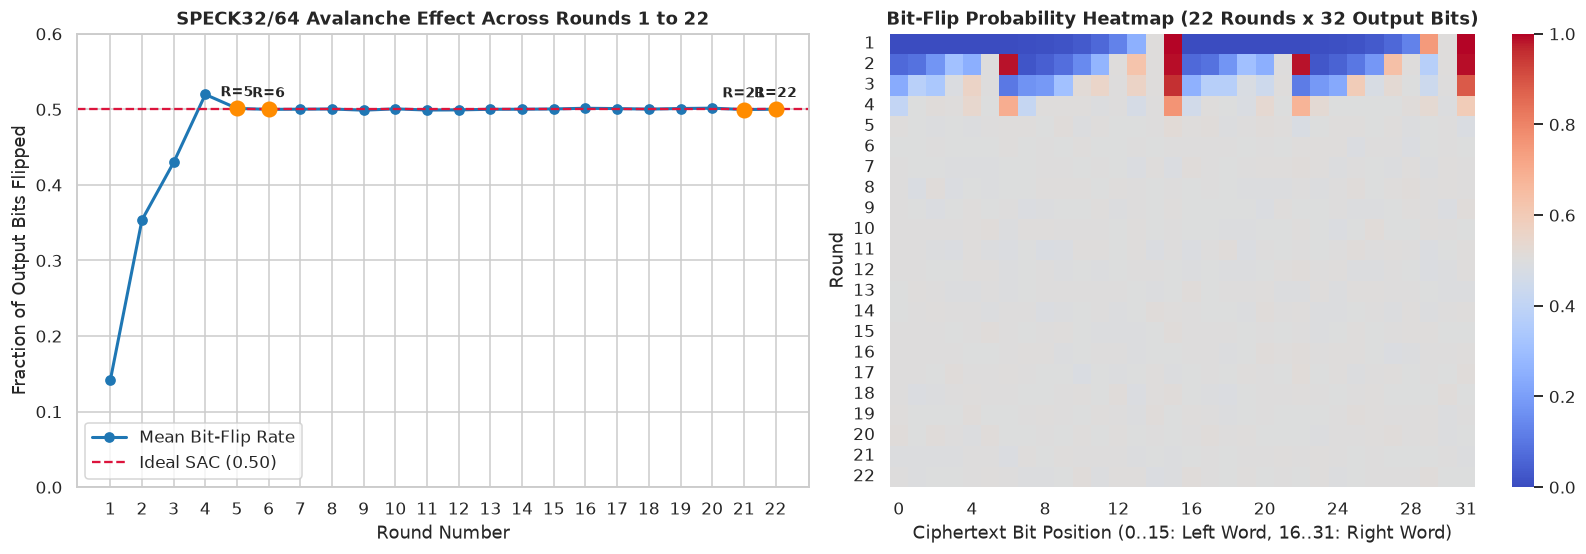

In [7]:
n_avalanche = 10_000
rng_av = np.random.default_rng(2026)
pt_x = rng_av.integers(0, 0x10000, size=n_avalanche, dtype=np.uint16)
pt_y = rng_av.integers(0, 0x10000, size=n_avalanche, dtype=np.uint16)

cipher = Speck32_64(key=PAPER_KEY_1_BYTES, rounds=22)
bit_flip_matrix = np.zeros((22, 32), dtype=np.float64)
mean_hamming_frac = []

cx1, cy1 = pt_x.copy(), pt_y.copy()
cx2, cy2 = pt_x.copy(), (pt_y ^ np.uint16(1)).copy()

for r in range(1, 23):
    rk = np.uint16(cipher.round_keys[r - 1])
    cx1, cy1 = enc_round(cx1, cy1, rk)
    cx2, cy2 = enc_round(cx2, cy2, rk)

    diff_bits = convert_to_binary_32(cx1 ^ cx2, cy1 ^ cy2)
    per_bit_prob = diff_bits.mean(axis=0)
    bit_flip_matrix[r - 1] = per_bit_prob
    mean_hamming_frac.append(per_bit_prob.mean())

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
rounds_axis = np.arange(1, 23)

axes[0].plot(rounds_axis, mean_hamming_frac, marker="o", linewidth=2, color="#1f77b4", label="Mean Bit-Flip Rate")
axes[0].axhline(0.50, color="crimson", linestyle="--", linewidth=1.5, label="Ideal SAC (0.50)")
for pr in [5, 6, 21, 22]:
    axes[0].scatter([pr], [mean_hamming_frac[pr - 1]], color="darkorange", s=90, zorder=5)
    axes[0].annotate(f"R={pr}", (pr, mean_hamming_frac[pr - 1]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold")
axes[0].set_xticks(rounds_axis)
axes[0].set_ylim(0.0, 0.60)
axes[0].set_title("SPECK32/64 Avalanche Effect Across Rounds 1 to 22", fontweight="bold")
axes[0].set_xlabel("Round Number")
axes[0].set_ylabel("Fraction of Output Bits Flipped")
axes[0].legend()

sns.heatmap(
    bit_flip_matrix, cmap="coolwarm", center=0.50, vmin=0.0, vmax=1.0, ax=axes[1],
    xticklabels=[0, "", "", "", 4, "", "", "", 8, "", "", "", 12, "", "", "", 16, "", "", "", 20, "", "", "", 24, "", "", "", 28, "", "", 31],
    yticklabels=rounds_axis,
)
axes[1].set_title("Bit-Flip Probability Heatmap (22 Rounds x 32 Output Bits)", fontweight="bold")
axes[1].set_xlabel("Ciphertext Bit Position (0..15: Left Word, 16..31: Right Word)")
axes[1].set_ylabel("Round")

plt.tight_layout()
plt.show()


## 6. Key Takeaways Across Rounds 1 → 22

1. **Random-IV CBC Holds Across All 22 Rounds (`~0.50`):** Both DeepAnalyst (`exp_a_r1_22.csv`) and TransferAnalyst (`exp_b_r1_22.csv`) stay at random guessing from Round 1 through Round 22 because a uniform 32-bit IV blinds single-block inputs before encryption.
2. **Gohr Differential Distinguisher Maps the True Cryptanalytic Boundary (`exp_c_gohr_r1_22.csv`):** Using the exact same 1D-ResNet architecture over unseen random keys, accuracy declines smoothly from **100.0% (`R=1`) → 99.9% (`R=2`) → 99.6% (`R=3`) → 94.9% (`R=4`) → 85.9% (`R=5`) → 66.2% (`R=6`)** before reaching the **~50% noise floor at `R ≥ 7`** (with 50k training samples).
3. **Avalanche Diffusion Matches Cryptanalytic Hardness:** Single-bit diffusion saturates to the `0.50` Strict Avalanche Criterion by rounds `5–6`, matching where differential accuracy rapidly decays and confirming strong security through full 22-round SPECK32/64.
